# YOLOv8 Drone Detection Fine-tuning

Complete notebook for fine-tuning a pre-trained YOLOv8 model on a new drone dataset.

## Dataset Format
- Images: JPG files in train/val/test folders
- Labels: YOLO format (class_id x_center y_center width height - normalized)
- Class: 0 = drone

## 1. Install Required Packages

In [5]:
# Install Ultralytics YOLO
!pip install ultralytics

In [6]:
# Verify GPU is available
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: Running on CPU. Go to Runtime -> Change runtime type -> Hardware accelerator -> GPU")

CUDA available: True
Device: Tesla T4


In [7]:
# ========== KEEP SESSION ALIVE ==========
# This clicks the connect button every minute to prevent timeout
from IPython.display import Javascript
display(Javascript('''
function ClickConnect(){
  console.log("Keeping session alive...");
  var button = document.querySelector("colab-connect-button");
  if(button) button.click();
}
setInterval(ClickConnect, 60000)
'''))

print("✓ Auto-reconnect enabled")

<IPython.core.display.Javascript object>

✓ Auto-reconnect enabled


## 2. Mount Google Drive

We need access to your Drive to get the dataset and save the results.

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Prepare Data

Copying data from Drive to the local Colab VM (`/content`) is much faster for training than reading directly from Drive.

**Note:** This notebook fine-tunes a pre-trained model on a new dataset. Make sure you have a trained model saved in your Drive from a previous training run.

In [9]:
import os
import shutil
from pathlib import Path

# Define path for the new dataset in Drive
new_dataset_zip = '/content/drive/MyDrive/AI_PROJECT/new_dataset.zip'
new_dataset_root = '/content/new_dataset'

if not os.path.exists(new_dataset_zip):
    print(f"Error: Could not find {new_dataset_zip}. Please make sure you uploaded new_dataset.zip to the 'yolov8_project' folder in Drive.")
else:
    print("Found new dataset zip.")

    # Unzip
    if os.path.exists(new_dataset_root):
        shutil.rmtree(new_dataset_root)
    os.makedirs(new_dataset_root, exist_ok=True)

    print("Unzipping...")
    !unzip -q "{new_dataset_zip}" -d "{new_dataset_root}"
    print("Unzip complete.")


Found new dataset zip.
Unzipping...
Unzip complete.


## 4. Import Libraries and Setup

Now we'll import all the necessary libraries for fine-tuning.


In [10]:
import os
import shutil
import yaml
from pathlib import Path
from ultralytics import YOLO
import torch

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Using device: cuda


## 5. Configuration

Configure your dataset paths and fine-tuning parameters here. Adjust these values based on your needs.


In [11]:
# ========== CONFIGURATION ==========
# Dataset paths
drive_project_path = '/content/drive/MyDrive/AI_PROJECT/yolov8_finetuning'
new_dataset_root = '/content/new_dataset/yolov8_finetuning_dataset'

# Pre-trained model path (from previous training run)
PRETRAINED_MODEL_PATH = f'/content/drive/MyDrive/AI_PROJECT/yolov8_project/runs/detect/train/weights/best.pt'

# Fine-tuning parameters
NUM_EPOCHS = 30             # Number of fine-tuning epochs
SAVE_PERIOD = 1              # Save checkpoint every N epochs
IMAGE_SIZE = 640             # Input image size
BATCH_SIZE = 16              # Batch size
NEW_DATA_YAML_PATH = '/content/new_dataset/yolov8_finetuning_dataset/dataset.yaml'

# Project settings
PROJECT_DIR = '/content/runs/detect'
RUN_NAME = 'finetune_drone_colab'

# Verify GPU is available
print("Configuration loaded!")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    print("WARNING: Running on CPU. Go to Runtime -> Change runtime type -> Hardware accelerator -> GPU")
print(f"\nFine-tuning settings:")
print(f"  Pre-trained model: {PRETRAINED_MODEL_PATH}")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Image size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"  Epochs: {NUM_EPOCHS}")


Configuration loaded!
CUDA available: True
Device: Tesla T4
GPU Memory: 14.74 GB

Fine-tuning settings:
  Pre-trained model: /content/drive/MyDrive/AI_PROJECT/yolov8_project/runs/detect/train/weights/best.pt
  Batch size: 16
  Image size: 640x640
  Epochs: 30


## 6. Create Configuration File

#We need to create a `new_data.yaml` that points to the local `/content/new_dataset` locations.
# Sometimes it unzips as /content/new_dataset/drone_dataset_split/... or just /content/new_dataset/...
# We'll look for the 'images' folder.

---



In [12]:

base_path = Path(new_dataset_root)
found_images = list(base_path.rglob('images'))

if not found_images:
    print("Error: Could not find 'images' folder after unzip.")
else:
    # Take the parent of the first 'images' folder found as the data root
    new_data_root = found_images[0].parent
    print(f"New data root located at: {new_dataset_root}")

    # Create new_data.yaml
    new_data_yaml = {
        'path': str(new_dataset_root),
        'train': 'images/train',
        'val': 'images/val',
        'test': 'images/test',
        'names': {0: 'drone'}  # Assuming same class mapping; update if different
    }

    with open(NEW_DATA_YAML_PATH, 'w') as f:
        yaml.dump(new_data_yaml, f)

    print(f"Created {new_data_root}/new_data.yaml")
    !cat {NEW_DATA_YAML_PATH}


New data root located at: /content/new_dataset/yolov8_finetuning_dataset
Created /content/new_dataset/yolov8_finetuning_dataset/new_data.yaml
names:
  0: drone
path: /content/new_dataset/yolov8_finetuning_dataset
test: images/test
train: images/train
val: images/val


## 7. Load Pre-trained Model

Now we'll load the pre-trained YOLOv8 model from your previous training run.


In [13]:
# Load the best model from previous training run
print(f"Loading pre-trained model from: {PRETRAINED_MODEL_PATH}")

if os.path.exists(PRETRAINED_MODEL_PATH):
    model = YOLO(PRETRAINED_MODEL_PATH)
    print("Model loaded successfully!")
else:
    print(f"Error: Model not found at {PRETRAINED_MODEL_PATH}")
    print("Please ensure you have completed training and saved the model to Drive.")
    print("Checking available weights...")
    if os.path.exists(f'{drive_project_path}/runs/detect'):
        print(os.listdir(f'{drive_project_path}/runs/detect'))


Loading pre-trained model from: /content/drive/MyDrive/AI_PROJECT/yolov8_project/runs/detect/train/weights/best.pt
Model loaded successfully!


## 8. Fine-tune Model

This is where the magic happens! The model will learn from the new dataset while leveraging knowledge from the pre-trained model. Fine-tuning may take a while depending on your dataset size and number of epochs.

**Note:** The best model (lowest validation loss) will be saved automatically during fine-tuning.


In [14]:
# ========== RESUME-SAFE TRAINING WITH BACKBONE FREEZING ==========
import os
import shutil
import glob
import time
import torch
from ultralytics import YOLO

# CRITICAL: Create checkpoint directory in Drive
CHECKPOINT_DIR = f'{drive_project_path}/checkpoints/{RUN_NAME}'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
print(f"Checkpoint directory: {CHECKPOINT_DIR}")

# ========== RESUME LOGIC WITH CORRUPTION CHECK ==========
def is_checkpoint_valid(checkpoint_path):
    """Check if a checkpoint file is valid and not corrupted"""
    try:
        if not os.path.exists(checkpoint_path):
            return False
        # Try to load metadata onto CPU
        torch.load(checkpoint_path, map_location='cpu', weights_only=False)
        return True
    except Exception:
        return False

def find_latest_checkpoint():
    """Find the most recent VALID checkpoint to resume from"""
    local_last = f'{PROJECT_DIR}/{RUN_NAME}/weights/last.pt'
    drive_last = f'{CHECKPOINT_DIR}/last.pt'
    checkpoints = []

    if is_checkpoint_valid(local_last):
        checkpoints.append(('local', local_last, os.path.getmtime(local_last)))
        print(f"✓ Found valid local checkpoint: {local_last}")

    if is_checkpoint_valid(drive_last):
        checkpoints.append(('drive', drive_last, os.path.getmtime(drive_last)))
        print(f"✓ Found valid Drive checkpoint: {drive_last}")

    epoch_checkpoints = glob.glob(f'{CHECKPOINT_DIR}/epoch*.pt')
    for ckpt in epoch_checkpoints:
        if is_checkpoint_valid(ckpt):
            checkpoints.append(('drive', ckpt, os.path.getmtime(ckpt)))

    if not checkpoints:
        return None, None

    checkpoints.sort(key=lambda x: x[2], reverse=True)
    location, path, _ = checkpoints[0]
    return location, path

def setup_model_for_training():
    """Setup model - either resume from checkpoint or start fresh"""
    print("=" * 60)
    print("Checking for existing checkpoints...")
    print("=" * 60)

    location, checkpoint_path = find_latest_checkpoint()

    if checkpoint_path:
        print(f"\n🔄 RESUMING TRAINING from {location} checkpoint")
        if location == 'drive':
            local_checkpoint = f'{PROJECT_DIR}/{RUN_NAME}/weights/last.pt'
            os.makedirs(os.path.dirname(local_checkpoint), exist_ok=True)
            shutil.copy2(checkpoint_path, local_checkpoint)
            checkpoint_path = local_checkpoint
            print(f"✓ Copied to local: {checkpoint_path}")

        model = YOLO(checkpoint_path)
        return model, True
    else:
        print("\n🆕 STARTING FRESH TRAINING (Recommended for Layer Freezing)")
        model = YOLO(PRETRAINED_MODEL_PATH) if os.path.exists(PRETRAINED_MODEL_PATH) else YOLO('yolov8n.pt')
        return model, False

# ========== THE ROCK-SOLID BACKUP CALLBACK ==========
def create_checkpoint_callback():
    def on_fit_epoch_end(trainer):
        epoch = trainer.epoch
        local_last = os.path.join(trainer.save_dir, 'weights', 'last.pt')
        local_best = os.path.join(trainer.save_dir, 'weights', 'best.pt')

        print(f"\n💾 Epoch {epoch + 1} complete. Syncing to Drive...")
        time.sleep(3)

        if is_checkpoint_valid(local_last):
            try:
                shutil.copy2(local_last, f'{CHECKPOINT_DIR}/last.pt')
                shutil.copy2(local_last, f'{CHECKPOINT_DIR}/epoch{epoch + 1}.pt')
                if os.path.exists(local_best) and is_checkpoint_valid(local_best):
                    shutil.copy2(local_best, f'{CHECKPOINT_DIR}/best.pt')
                print(f"✅ Drive Sync Successful: epoch{epoch + 1}.pt")
            except Exception as e:
                print(f"❌ Drive Sync Error: {e}")
        else:
            print(f"⚠️ Warning: 'last.pt' busy. Skipping Drive backup.")

    return on_fit_epoch_end

# ========== INITIALIZE & RUN ==========
model, is_resuming = setup_model_for_training()

# Register callback
model.add_callback("on_fit_epoch_end", create_checkpoint_callback())

print(f"\n🚀 Starting Training")
print(f"   - Freeze Backbone: layers 0-10")
print(f"   - Multi-Scale: Enabled")
print(f"   - Learning Rate: 0.001 (Stable)")

# Start Training
results = model.train(
    data=NEW_DATA_YAML_PATH,
    epochs=NUM_EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,
    resume=is_resuming,
    save=True,
    freeze=10,         # <--- FREEZE FIRST 10 LAYERS
    lr0=0.001,         # <--- LOWER LEARNING RATE
    multi_scale=True,  # <--- BETTER SCALE INVARIANCE
    device=0 if torch.cuda.is_available() else 'cpu'
)

# ========== FINAL BACKUP ==========
print("\n" + "="*30)
print("Finalizing weights...")
for f_name in ['best.pt', 'last.pt']:
    src = os.path.join(PROJECT_DIR, RUN_NAME, 'weights', f_name)
    if os.path.exists(src):
        shutil.copy2(src, f'{CHECKPOINT_DIR}/final_{f_name}')
print("✅ Training session ended and backed up!")

Checkpoint directory: /content/drive/MyDrive/AI_PROJECT/yolov8_finetuning/checkpoints/finetune_drone_colab
Checking for existing checkpoints...

🆕 STARTING FRESH TRAINING (Recommended for Layer Freezing)

🚀 Starting Training
   - Freeze Backbone: layers 0-10
   - Multi-Scale: Enabled
   - Learning Rate: 0.001 (Stable)
Ultralytics 8.3.240 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/new_dataset/yolov8_finetuning_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz

## 9. View Training History

Let's visualize how the fine-tuning progressed over time. YOLOv8 automatically generates training plots that are saved in the runs directory.


Fine-tuning results visualization:


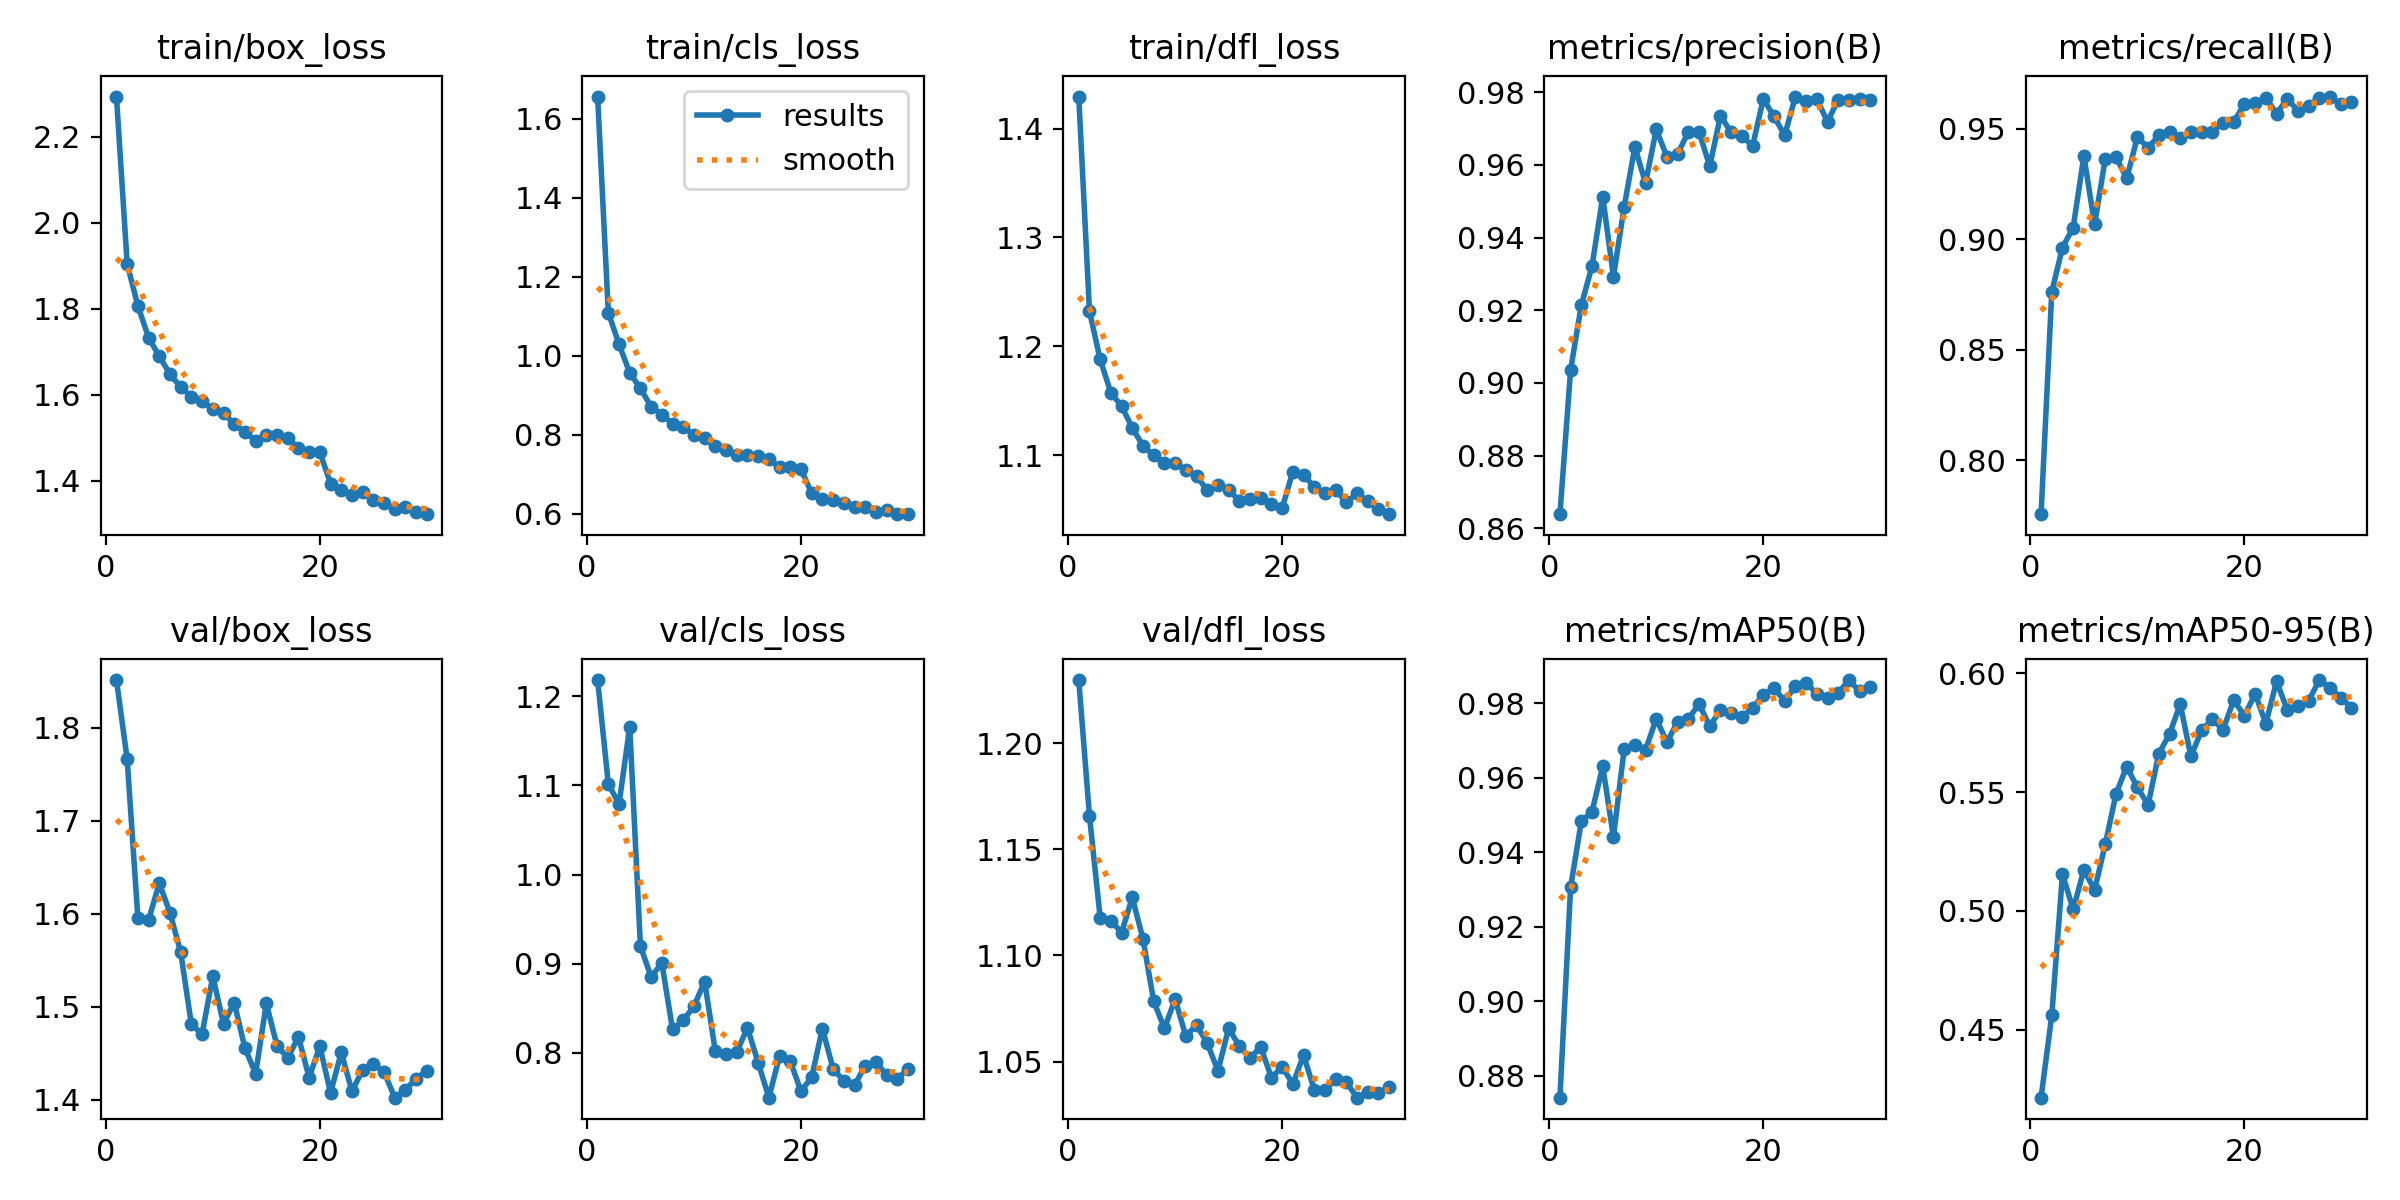

In [15]:
import matplotlib.pyplot as plt
from IPython.display import Image, display
import glob

# Display training results
results_dir = f'{PROJECT_DIR}/{RUN_NAME}'
results_image = f'{results_dir}/results.png'

if os.path.exists(results_image):
    print("Fine-tuning results visualization:")
    display(Image(results_image))
else:
    print(f"Results image not found at {results_image}")
    print("Available files in results directory:")
    if os.path.exists(results_dir):
        print(glob.glob(f'{results_dir}/*'))


## 10. Evaluate Model

Let's evaluate the fine-tuned model on the test dataset to see how well it performs.


In [16]:
# Load your best fine-tuned model from the fine-tuning results
model_path = f'{results_dir}/weights/best.pt'
if os.path.exists(model_path):
    print(f"Loading best model from: {model_path}")
    model = YOLO(model_path)

    # Run validation on the test split defined in new_data.yaml
    print("\nEvaluating on test dataset...")
    metrics = model.val(data=NEW_DATA_YAML_PATH, split='test')

    print(f"\nEvaluation Results:")
    print(f"  mAP50-95: {metrics.box.map:.4f}")
    print(f"  mAP50: {metrics.box.map50:.4f}")
else:
    print(f"Model not found at {model_path}")
    print("Please ensure fine-tuning completed successfully.")


Loading best model from: /content/runs/detect/finetune_drone_colab/weights/best.pt

Evaluating on test dataset...
Ultralytics 8.3.240 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLOv8n summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 26.2±10.9 MB/s, size: 116.3 KB)
val: Scanning /content/new_dataset/yolov8_finetuning_dataset/labels/test... 5957 images, 443 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5957/5957 484.2it/s 12.3s
val: New cache created: /content/new_dataset/yolov8_finetuning_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 373/373 5.2it/s 1:11
                   all       5957       5514      0.884      0.762      0.836      0.411
Speed: 0.9ms preprocess, 2.6ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val

Evaluation Results:
  mAP50-95: 0.4110
  mAP50

## 11. Test Model on Validation Images

Let's see how well the model performs by visualizing predictions on some validation/test images.


Predicting on: /content/new_dataset/yolov8_finetuning_dataset/images/test/20190925_124612_1_1_I0590.jpg

image 1/1 /content/new_dataset/yolov8_finetuning_dataset/images/test/20190925_124612_1_1_I0590.jpg: 384x640 1 drone, 44.3ms
Speed: 2.6ms preprocess, 44.3ms inference, 2.3ms postprocess per image at shape (1, 3, 384, 640)


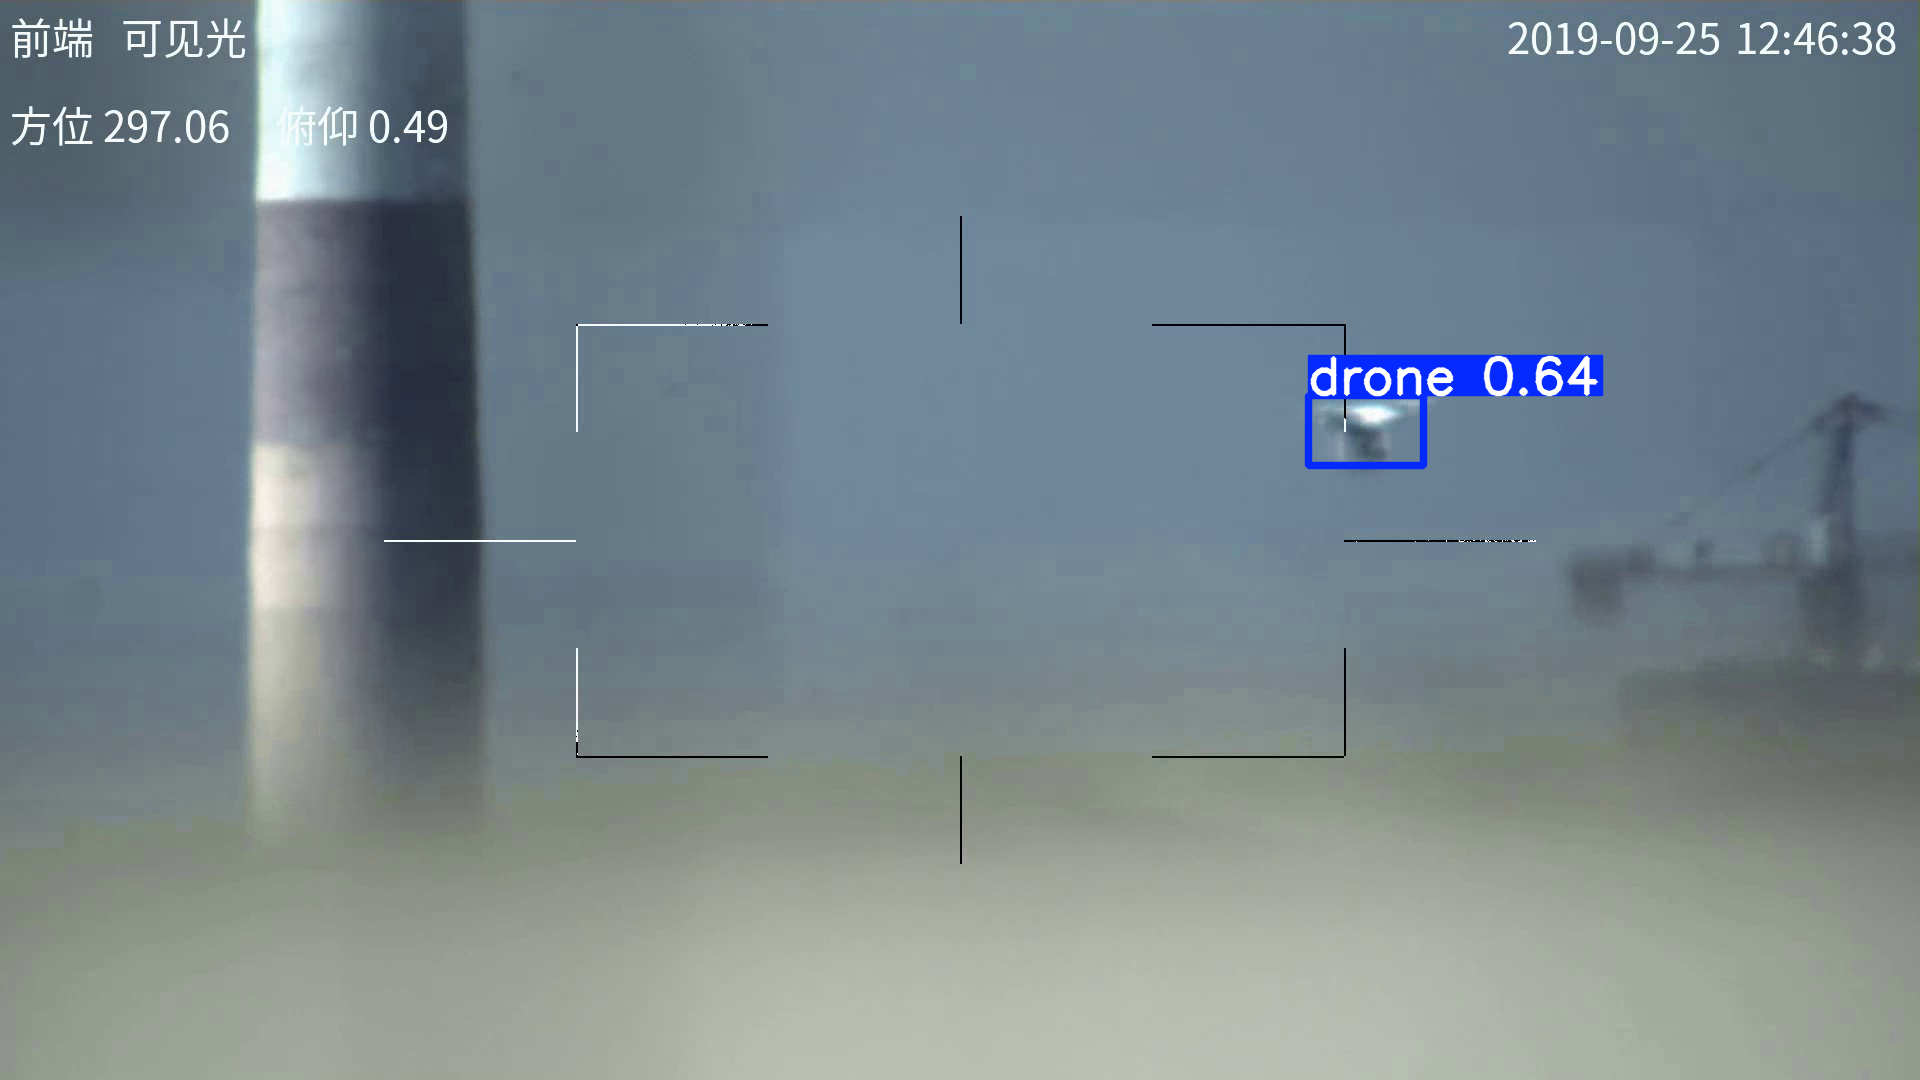

In [17]:
import random
import glob
from PIL import Image
from IPython.display import display

# Path to your test images based on your new dataset root
# Use new_data_root from the configuration file creation step
test_images_path = f'{new_data_root}/images/test/*.jpg'
test_images = glob.glob(test_images_path)

if not test_images:
    print("No images found in the test folder.")
else:
    # Select a random image
    random_image = random.choice(test_images)

    # Run prediction
    print(f"Predicting on: {random_image}")
    results = model.predict(source=random_image, conf=0.25)

    # Visualize the results
    for r in results:
        im_array = r.plot()  # plot a BGR numpy array of predictions
        im = Image.fromarray(im_array[..., ::-1])  # convert to RGB PIL image
        display(im)


## 12. Test Model on Uploaded Images

You can test the model on your own images by uploading them.

Please select an image to upload:


Saving how-far-fly-drone-768x554.jpg to how-far-fly-drone-768x554 (1).jpg

Running prediction on: how-far-fly-drone-768x554 (1).jpg

image 1/1 /content/how-far-fly-drone-768x554 (1).jpg: 480x640 1 drone, 10.3ms
Speed: 3.2ms preprocess, 10.3ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 640)


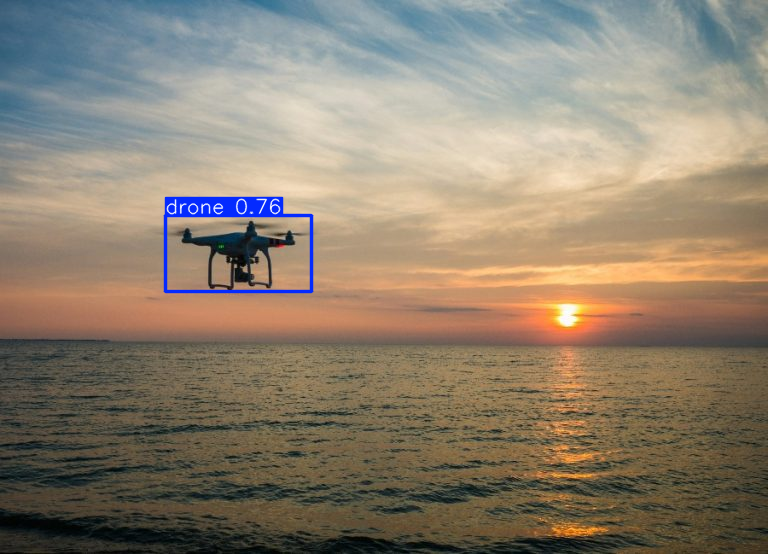

In [27]:
from google.colab import files

# Ensure model is loaded
if 'model' not in locals() or model is None:
    model_path = f'{results_dir}/weights/best.pt'
    if os.path.exists(model_path):
        model = YOLO(model_path)
        print(f"Loaded model from: {model_path}")
    else:
        print("Error: Model not found. Please run fine-tuning first.")

# Upload your image
print("Please select an image to upload:")
uploaded = files.upload()

# Process the uploaded file(s)
for filename in uploaded.keys():
    print(f'\nRunning prediction on: {filename}')

    # Run prediction
    results = model.predict(source=filename, conf=0.25)

    # Visualize and display the results
    for r in results:
        im_array = r.plot()  # plot a BGR numpy array of predictions
        im = Image.fromarray(im_array[..., ::-1])  # convert to RGB PIL image
        display(im)


## 13. Save Results to Drive

Compress the fine-tuning results and copy them back to Google Drive for safekeeping.

In [21]:
# Compress the fine-tuning results
zip_path = f'{results_dir}/runs_finetune.zip'
!zip -r {zip_path} {results_dir}

# Copy to Drive
destination = f'{drive_project_path}/runs_finetune.zip'
shutil.copy2(zip_path, destination)

print(f"✓ Results saved to Google Drive: {destination}")
print("\n🎉 ALL DONE! Your fine-tuned model is saved in Google Drive.")


updating: content/runs/detect/finetune_drone_colab/ (stored 0%)
updating: content/runs/detect/finetune_drone_colab/train_batch12960.jpg (deflated 27%)
updating: content/runs/detect/finetune_drone_colab/val_batch2_labels.jpg (deflated 24%)
updating: content/runs/detect/finetune_drone_colab/val_batch0_pred.jpg (deflated 15%)
updating: content/runs/detect/finetune_drone_colab/train_batch1.jpg (deflated 16%)
updating: content/runs/detect/finetune_drone_colab/results.png (deflated 8%)
updating: content/runs/detect/finetune_drone_colab/val_batch0_labels.jpg (deflated 16%)
updating: content/runs/detect/finetune_drone_colab/train_batch12961.jpg (deflated 26%)
updating: content/runs/detect/finetune_drone_colab/BoxF1_curve.png (deflated 15%)
updating: content/runs/detect/finetune_drone_colab/weights/ (stored 0%)
updating: content/runs/detect/finetune_drone_colab/weights/best.pt (deflated 10%)
updating: content/runs/detect/finetune_drone_colab/weights/last.pt (deflated 10%)
updating: content/runs